In [1]:
%reload_ext autoreload
%autoreload 2
from IPython.display import Math
from tqdm import tqdm
import sys
import os
from tqdm import tqdm
parent_path = os.path.abspath("..")
if parent_path not in sys.path:
    sys.path.append(parent_path)

# For a quick config:
# import logging
# logging.basicConfig(
#     format="%(asctime)s [%(levelname)s] [%(name)s]: %(message)s",
#     level=logging.DEBUG
# )

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import sympy
import numpy as np
import numpy.typing as npt
import typing
from typing import Callable, Dict, List, Optional, Tuple, Union, Iterable
import qutip # type: ignore

from src.quantum_utils import measure_povm
from src.quantum_utils import random_kets
from src.quantum_utils import QuantumStatesBatch, QuantumKetsBatch, QuantumOperatorsBatch, QuantumState, QuantumKet, QuantumOperator, POVM
from src.povms import sic_povm, mub_povm, random_rank1_povm
from src.qelm_utils import analyze_biasvar_vs_nstates, analyze_biasvar_vs_statistics

from src.shadow_tomography import frame_operator
from src.utils import pp_matrix
from src.QELM import QELM, TrainingData

def counts_to_frequencies(counts, n_qubits, shots=None, little_endian=True):
    """
    Convert Qiskit counts dict to a normalized frequency vector.

    Parameters
    ----------
    counts : dict
        Dictionary from Qiskit result.get_counts(), mapping bitstring->count.
    n_qubits : int
        Total number of qubits measured.
    shots : int or None
        Total number of shots. If None, sum(counts.values()) is used.
    little_endian : bool
        If True, interpret rightmost bit as qubit 0 (Qiskit default).
        If False, interpret leftmost bit as qubit 0.

    Returns
    -------
    freqs : np.ndarray
        Array of shape (2**n_qubits,) with normalized frequencies.
    """
    if shots is None:
        shots = sum(counts.values())

    freqs = np.zeros(2**n_qubits, dtype=float)

    for bitstring, c in counts.items():
        index = int(bitstring[::-1], 2) if little_endian else int(bitstring, 2)
        freqs[index] = c / shots

    return freqs


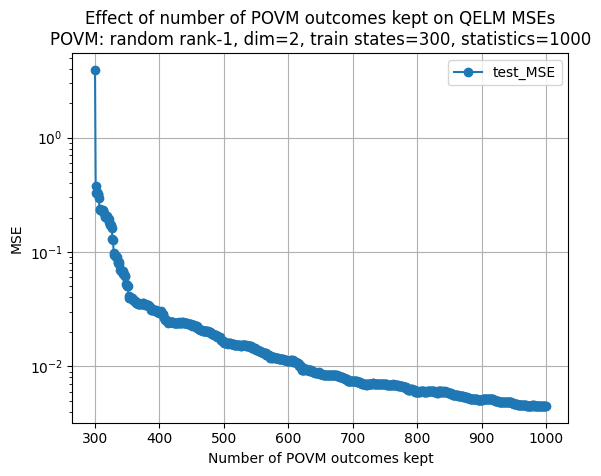

In [ ]:
# train a QELM with a rank-1 POVM obtained from a random unitary
dim = 2
n_train_states = 300
# n_test_states = 50
train_stat = 1000
num_outcomes = 1000
povm = random_rank1_povm(dim=dim, num_outcomes=num_outcomes)
target_observable = QuantumOperator(qutip.sigmax().full())
train_states = QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_states))
test_states = QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_states))

train_frequencies = train_states.measure_povm(povm, statistics=train_stat, return_frequencies=True)
test_frequencies = test_states.measure_povm(povm, statistics=train_stat, return_frequencies=True)
# test_frequencies = test_states.measure_povm(povm, statistics=train_stat, return_frequencies=True)
train_expvals = train_states.expvals(observables=target_observable)
test_expvals = test_states.expvals(observables=target_observable)
# test_expvals = test_states.expvals(observables=target_observable)

data = []
for kept_outcomes in range(n_train_states, num_outcomes + 1):
    train_frequencies_ = train_frequencies[:kept_outcomes, :]
    test_frequencies_ = test_frequencies[:kept_outcomes, :]
    train_data = TrainingData(frequencies=train_frequencies_, labels=train_expvals)
    test_data = TrainingData(frequencies=test_frequencies_, labels=test_expvals)
    qelm = QELM(train=train_data, test=test_data)
    qelm = qelm.compute_MSE(train=True, test=True, display_results=False)
    data.append((kept_outcomes, qelm.train_MSE[0], qelm.test_MSE[0]))
    # print(f"kept outcomes: {kept_outcomes}, train MSE: {mse}")
# remove train MSE from data
data = [(x[0], x[2]) for x in data]
df = pd.DataFrame(data, columns=["kept_outcomes", "test_MSE"])
df.set_index("kept_outcomes", inplace=True)
df.plot(marker='o', logy=True)
plt.xlabel("Number of POVM outcomes kept")
plt.ylabel("MSE")
plt.title(f"Effect of number of POVM outcomes kept on QELM MSEs\n"
          f"POVM: random rank-1, dim={dim}, train states={n_train_states}, statistics={train_stat}")
plt.grid(True)
plt.show()


number of outcomes: 100%|██████████| 100/100 [31:40<00:00, 19.00s/run]


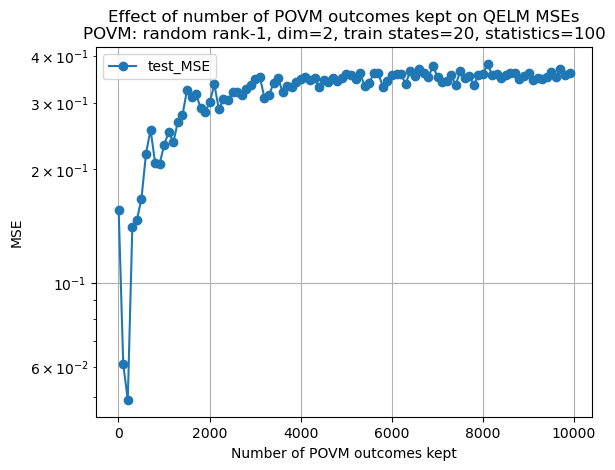

In [11]:
# train a QELM with a rank-1 POVM obtained from a random unitary
dim = 2
n_train_states = 20
# n_test_states = 50
train_stat = 100

target_observable = QuantumOperator(qutip.sigmax().full())
train_states = QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_states))
test_states = QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_states))
train_expvals = train_states.expvals(observables=target_observable)
test_expvals = test_states.expvals(observables=target_observable)
# test_expvals = test_states.expvals(observables=target_observable)

data = []

for num_outcomes in tqdm(range(4, 10000 + 1, 100), desc="number of outcomes", unit="run"):
    povm = random_rank1_povm(dim=dim, num_outcomes=num_outcomes)
    train_frequencies = train_states.measure_povm(povm, statistics=train_stat, return_frequencies=True)
    test_frequencies = test_states.measure_povm(povm, statistics=train_stat, return_frequencies=True)
    train_data = TrainingData(frequencies=train_frequencies, labels=train_expvals)
    test_data = TrainingData(frequencies=test_frequencies, labels=test_expvals)
    qelm = QELM(train=train_data, test=test_data)
    qelm = qelm.compute_MSE(train=True, test=True, display_results=False)
    data.append((num_outcomes, qelm.train_MSE[0], qelm.test_MSE[0]))
    # print(f"kept outcomes: {kept_outcomes}, train MSE: {mse}")
# remove train MSE from data
data = [(x[0], x[2]) for x in data]
df = pd.DataFrame(data, columns=["kept_outcomes", "test_MSE"])
df.set_index("kept_outcomes", inplace=True)
df.plot(marker='o', logy=True)
plt.xlabel("Number of POVM outcomes kept")
plt.ylabel("MSE")
plt.title(f"Effect of number of POVM outcomes kept on QELM MSEs\n"
          f"POVM: random rank-1, dim={dim}, train states={n_train_states}, statistics={train_stat}")
plt.grid(True)
plt.show()


number of outcomes: 100%|██████████| 108/108 [01:37<00:00,  1.10run/s]


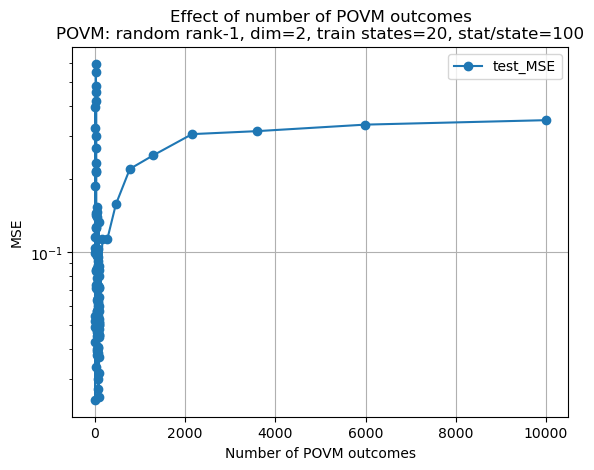

In [50]:
# train a QELM with a rank-1 POVM obtained from a random unitary
dim = 2
n_train_states = 20
# n_test_states = 50
train_stat = 100

target_observable = QuantumOperator(qutip.sigmax().full())
train_states = QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_states))
test_states = QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_states))
train_expvals = train_states.expvals(observables=target_observable)
test_expvals = test_states.expvals(observables=target_observable)
# test_expvals = test_states.expvals(observables=target_observable)

data = []

outcomes_list = list(range(2, 100)) + list(np.logspace(np.log10(100), np.log10(10000), num=10).astype(int))
for num_outcomes in tqdm(outcomes_list, desc="number of outcomes", unit="run"):
    povm = random_rank1_povm(dim=dim, num_outcomes=num_outcomes)
    train_frequencies = train_states.measure_povm(povm, statistics=train_stat, return_frequencies=True)
    test_frequencies = test_states.measure_povm(povm, statistics=train_stat, return_frequencies=True)
    train_data = TrainingData(frequencies=train_frequencies, labels=train_expvals)
    test_data = TrainingData(frequencies=test_frequencies, labels=test_expvals)
    qelm = QELM(train=train_data, test=test_data)
    qelm = qelm.compute_MSE(train=True, test=True, display_results=False)
    data.append((num_outcomes, qelm.train_MSE[0], qelm.test_MSE[0]))
    # print(f"kept outcomes: {kept_outcomes}, train MSE: {mse}")
# remove train MSE from data
data = [(x[0], x[2]) for x in data]
df = pd.DataFrame(data, columns=["kept_outcomes", "test_MSE"])
df.set_index("kept_outcomes", inplace=True)
df.plot(marker='o', logy=True)
plt.xlabel("Number of POVM outcomes")
plt.ylabel("MSE")
plt.title(f"Effect of number of POVM outcomes\n"
          f"POVM: random rank-1, dim={dim}, train states={n_train_states}, stat/state={train_stat}")
plt.grid(True)
plt.show()


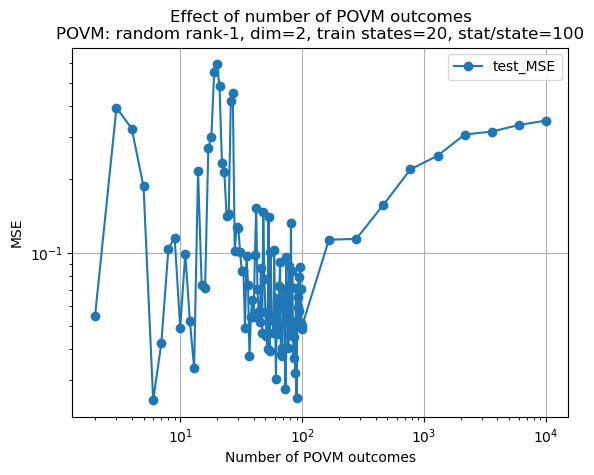

In [51]:
df.plot(marker='o', logy=True, logx=True)
plt.xlabel("Number of POVM outcomes")
plt.ylabel("MSE")
plt.title(f"Effect of number of POVM outcomes\n"
          f"POVM: random rank-1, dim={dim}, train states={n_train_states}, stat/state={train_stat}")
plt.grid(True)
plt.show()

## Observe that throwing information away CAN improve performances

Using 2+1 qubits

In [ ]:
U = random_unitary(4)
gate = UnitaryGate(U.data, label="U")

input_state = train_states[run]

qc = QuantumCircuit(3, 3)
qc.prepare_state(input_state, [0, 1])
# prepare third qubit on |+>
qc.h(2)

qc.append(gate, [0, 1])
qc.measure(range(3), range(3))

sim = AerSimulator()              # qasm-style sampling
qc_sim = transpile(qc, sim, optimization_level=0)

# Draw samples
result = sim.run(qc_sim, shots=stat_per_state).result()

In [ ]:
class MeasurementApparatus():
    def __init__(self, input_dim: int):
        self.input_dim = input_dim
        # self.registers = ['input']
        self.steps = []
    
    def add_ancilla_register(self, label: str, state: QuantumState) -> MeasurementApparatus:
        """Add ancilla register."""
        self.steps.append(('add_ancilla', label, state))
        return self

    def apply_unitary(self, labels: str, unitary: QuantumOperator) -> MeasurementApparatus:
        """Apply unitary operation.
        
        labels: str
            Comma-separated labels of registers the unitary acts on.
        """
        self.steps.append(('apply_unitary', label, unitary))
        return self
    
    def measure_register(self, label: str, basis: Optional[QuantumOperator] = None) -> MeasurementApparatus:
        """Measure register in specified basis."""
        self.steps.append(('measure', label, basis))
        return self
    
    def effective_povm(self) -> POVM:
        """Compute the effective POVM implemented by the apparatus."""
        # this should be invoked after all steps have been added
        # It starts from the end, and whenever it sees a measurement step,
        # it constructs the POVM elements, propagating them backwards through
        # the unitaries and ancilla additions.
        # Ancilla additions are handled by reducing the operators appropriately projecting onto the ancilla state.
        # Unitaries are handled by conjugating the operators.
        # If there's register that aren't measured, in the Heisenberg picture these correspond to adding an identity

        # 

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import random_unitary
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
from numpy.random import random

n_train_states = 100
n_test_states = 100
stat_per_state = 100

# compute training states
train_states = random_kets(dim=4, num_kets=n_train_states)
test_states = random_kets(dim=4, num_kets=n_test_states)

U = random_unitary(4)
gate = UnitaryGate(U.data, label="U")

counts = []
for run in range(n_train_states):
    input_state = train_states[run]

    qc = QuantumCircuit(3, 3)
    qc.prepare_state(input_state, [0, 1])
    # prepare third qubit on |+>
    qc.h(2)

    qc.append(gate, [0, 1])
    qc.measure(range(3), range(3))

    sim = AerSimulator()              # qasm-style sampling
    qc_sim = transpile(qc, sim, optimization_level=0)

    # Draw samples
    result = sim.run(qc_sim, shots=stat_per_state).result()
    counts.append(result.get_counts())
train_frequencies = np.array([counts_to_frequencies(count, n_qubits=3) for count in counts]).T

counts = []
for run in range(n_test_states):
    input_state = test_states[run]

    qc = QuantumCircuit(3, 3)
    qc.prepare_state(input_state, [0, 1])
    # prepare third qubit on |+>
    qc.h(2)

    qc.append(gate, [0, 1])
    qc.measure(range(3), range(3))

    sim = AerSimulator()              # qasm-style sampling
    qc_sim = transpile(qc, sim, optimization_level=0)

    # Draw samples
    result = sim.run(qc_sim, shots=stat_per_state).result()
    counts.append(result.get_counts())
test_frequencies = np.array([counts_to_frequencies(count, n_qubits=3) for count in counts]).T



obs = np.kron(qutip.sigmax().full(), np.eye(2, dtype=complex))
train_states_ = QuantumKetsBatch(train_states)
train_expvals = train_states_.expvals(observables=QuantumOperator(obs))
test_states_ = QuantumKetsBatch(test_states)
test_expvals = test_states_.expvals(observables=QuantumOperator(obs))

train_data = TrainingData(frequencies=train_frequencies, labels=train_expvals)
test_data = TrainingData(frequencies=test_frequencies, labels=test_expvals)
qelm = QELM(train=train_data, test=test_data)
mse = qelm.compute_MSE(train=True, test=True, display_results=False)
mse.train_MSE, mse.test_MSE

(array([0.18575647]), array([0.20437612]))

In [104]:
# train_frequencies is an 8x100 array, where 8 is because there are 3 qubits measured, and each column represents the frequencies for one training state.
# Compute the marginal of each frequency vector over the last qubit

train_frequencies01 = train_frequencies.reshape(2,2,2,-1).sum(axis=2).reshape(4,-1)
test_frequencies01 = test_frequencies.reshape(2,2,2,-1).sum(axis=2).reshape(4,-1)
train_data01 = TrainingData(frequencies=train_frequencies01, labels=train_expvals)
test_data01 = TrainingData(frequencies=test_frequencies01, labels=test_expvals)
qelm = QELM(train=train_data01, test=test_data01)
mse = qelm.compute_MSE(train=True, test=True, display_results=False)
mse.train_MSE, mse.test_MSE

(array([0.11696804]), array([0.12626708]))

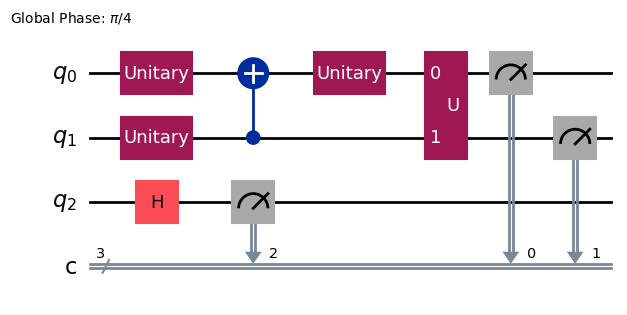

In [3]:
qc_sim.draw('mpl')

Same but now with only 1 qubit to reconstruct

[0.0373521] [0.06263515]


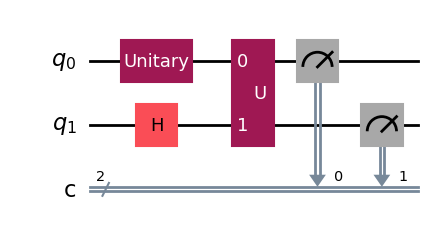

[0.31172395] [0.2912533]


In [109]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import random_unitary
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
from numpy.random import random

n_train_states = 20
n_test_states = 20
stat_per_state = 100

# compute training states
train_states = random_kets(dim=2, num_kets=n_train_states)
test_states = random_kets(dim=2, num_kets=n_test_states)

U = random_unitary(4)
gate = UnitaryGate(U.data, label="U")

counts = []
for run in range(n_train_states):
    input_state = train_states[run]

    qc = QuantumCircuit(2, 2)
    qc.prepare_state(input_state, (0,))
    # prepare second qubit on |+>
    qc.h(1)

    qc.append(gate, [0, 1])
    qc.measure(range(2), range(2))

    sim = AerSimulator()              # qasm-style sampling
    qc_sim = transpile(qc, sim, optimization_level=0)

    # Draw samples
    result = sim.run(qc_sim, shots=stat_per_state).result()
    counts.append(result.get_counts())
train_frequencies = np.array([counts_to_frequencies(count, n_qubits=3) for count in counts]).T

counts = []
for run in range(n_test_states):
    input_state = test_states[run]

    qc = QuantumCircuit(2, 2)
    qc.prepare_state(input_state, (0,))
    # prepare second qubit on |+>
    qc.h(1)

    qc.append(gate, [0, 1])
    qc.measure(range(2), range(2))

    sim = AerSimulator()              # qasm-style sampling
    qc_sim = transpile(qc, sim, optimization_level=0)

    # Draw samples
    result = sim.run(qc_sim, shots=stat_per_state).result()
    counts.append(result.get_counts())
test_frequencies = np.array([counts_to_frequencies(count, n_qubits=3) for count in counts]).T



obs = qutip.sigmax().full()
train_states_ = QuantumKetsBatch(train_states)
train_expvals = train_states_.expvals(observables=QuantumOperator(obs))
test_states_ = QuantumKetsBatch(test_states)
test_expvals = test_states_.expvals(observables=QuantumOperator(obs))

train_data = TrainingData(frequencies=train_frequencies, labels=train_expvals)
test_data = TrainingData(frequencies=test_frequencies, labels=test_expvals)
qelm = QELM(train=train_data, test=test_data)
mse = qelm.compute_MSE(train=True, test=True, display_results=False)
print(mse.train_MSE, mse.test_MSE)

display(qc_sim.draw('mpl'))

# train again but now with marginals

train_frequencies01 = train_frequencies.reshape(2,2,2,-1).sum(axis=2).reshape(4,-1)
test_frequencies01 = test_frequencies.reshape(2,2,2,-1).sum(axis=2).reshape(4,-1)
train_data01 = TrainingData(frequencies=train_frequencies01, labels=train_expvals)
test_data01 = TrainingData(frequencies=test_frequencies01, labels=test_expvals)
qelm = QELM(train=train_data01, test=test_data01)
mse = qelm.compute_MSE(train=True, test=True, display_results=False)
print(mse.train_MSE, mse.test_MSE)

In [65]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import random_unitary
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
from numpy.random import random

n = 10
n_inputs = 6
n_train_states = 100
# n_test_states = 50
train_stat = 100

# compute training states
train_states = random_kets(dim=2, num_kets=n_train_states * n_inputs)
full_states = []


U = random_unitary(2**n)
gate = UnitaryGate(U.data, label="U")

counts = []
for train_run in range(n_train_states):
    states = train_states[train_run * n_inputs : (train_run + 1) * n_inputs]

    qc = QuantumCircuit(n, n)
    # prepare random factorised input states on the first 6 qubits
    for i in range(n_inputs):
        qc.prepare_state(states[i], i)
    # rewrite the 5 states as a single state in the larger space (via tensor product)
    # compute tensor product of the states[i]
    full_state = states[0]
    for s in states[1:]:
        full_state = np.kron(full_state, s)
    full_states.append(full_state)

    qc.append(gate, range(n))
    qc.measure(range(n), range(n))

    # 3) Simulate with Aer. Keep the 'unitary' op; avoid basis decomposition.
    sim = AerSimulator()              # qasm-style sampling
    qc_sim = transpile(qc, sim, optimization_level=0)

    # 4) Draw samples
    
    result = sim.run(qc_sim, shots=train_stat).result()
    counts.append(result.get_counts())


In [69]:
frequencies = np.zeros((2**n, n_train_states))
for i, count in enumerate(counts):
    total_counts = sum(count.values())
    for bitstring, cnt in count.items():
        index = int(bitstring, 2)
        frequencies[index, i] = cnt / total_counts

train_states = QuantumKetsBatch(full_states)
X_local_first = np.kron(qutip.sigmax().full(), np.eye(2**(n_inputs-1), dtype=complex))
train_expvals = train_states.expvals(observables=QuantumOperator(X_local_first))
train_data = TrainingData(frequencies=frequencies, labels=train_expvals)
qelm = QELM(train=train_data)
mse = qelm.compute_MSE(train=True, test=False, display_results=False)
mse.train_MSE

array([1.91178799e-30])

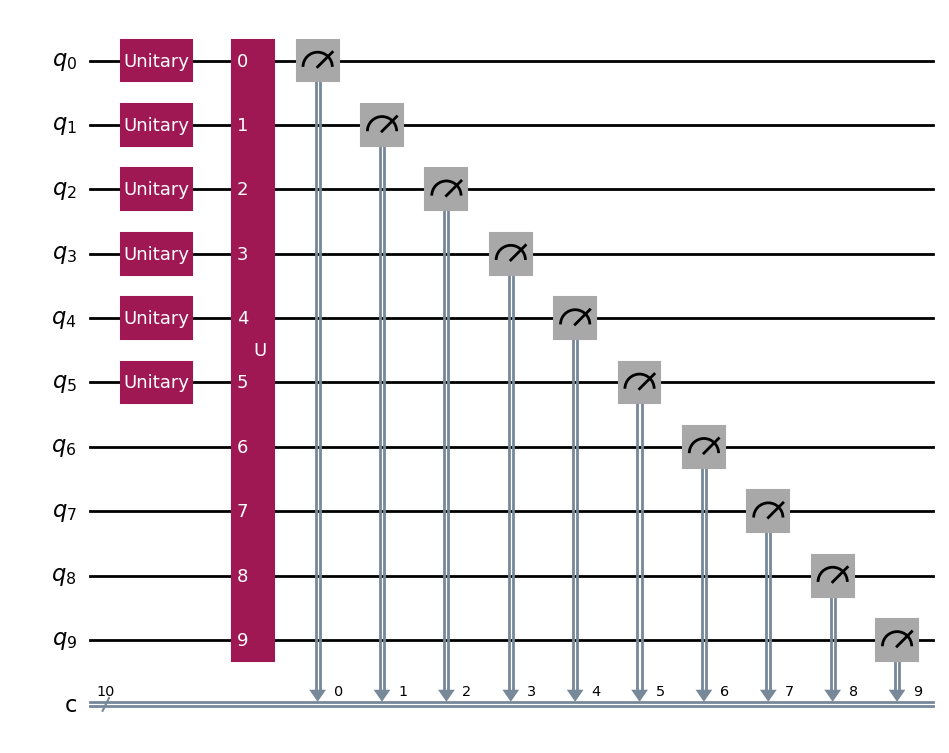

In [19]:
qc_sim.draw('mpl')

# MSE vs statistics for different number of outcomes

Drawing random povms with different dimensions:

realizations: 100%|██████████| 100/100 [00:05<00:00, 19.62it/s]


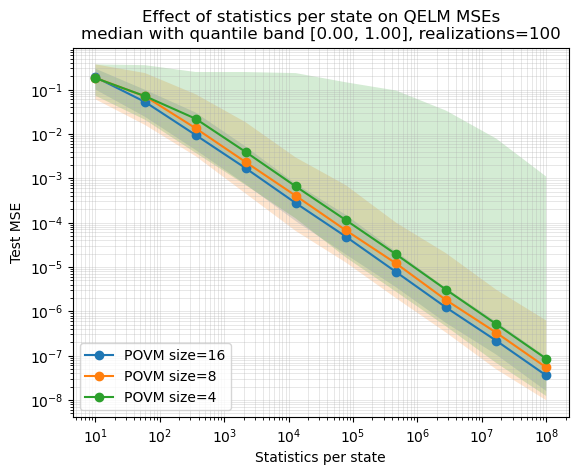

In [5]:
n_realizations = 100
dim = 2
num_outcomes = 2**4
n_train_kets = 100
n_test_kets = 100
stat_per_state_list = np.logspace(np.log10(10), np.log10(1e8), num=10).astype(int)
q_lo, q_hi = 0, 1      # e.g. IQR band; change to (0.1,0.9) etc.
# -----------------------------
# run many realizations
# -----------------------------
rows = []
for r in tqdm(range(n_realizations), desc="realizations"):
    povm_2 = random_rank1_povm(dim=2, num_outcomes=2**2)
    povm_3 = random_rank1_povm(dim=2, num_outcomes=2**3)
    povm_4 = random_rank1_povm(dim=2, num_outcomes=2**4)

    for povm_idx in range(3):
        povm = [povm_4, povm_3, povm_2][povm_idx]
        for stat_per_state in tqdm(stat_per_state_list, leave=False, desc=f"povm_idx={povm_idx}"):
            qelm = QELM.train_from_observables_and_states(
                target_observables=QuantumOperator(qutip.sigmax().full()),
                training_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_kets)),
                test_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_test_kets)),
                povm=povm,
                statistics=stat_per_state
            )
            qelm.compute_MSE(train=True, test=True, display_results=False)

            rows.append({
                "realization": r,
                "povm_size_idx": povm_idx,
                "povm_size": 2**(4 - povm_idx),
                "stat_per_state": stat_per_state,
                "train_MSE": float(qelm.train_MSE[0]),
                "test_MSE": float(qelm.test_MSE[0]),
            })

        # marginalize one output qubit: pairwise sum POVM elements
        povm = POVM(povm[0::2] + povm[1::2])

df = pd.DataFrame(rows)

# -----------------------------
# aggregate: median + quantiles over realizations
# -----------------------------
g = df.groupby(["povm_size_idx", "povm_size", "stat_per_state"])

agg = g.agg(
    test_median=("test_MSE", "median"),
    test_qlo=("test_MSE", lambda x: np.quantile(x, q_lo)),
    test_qhi=("test_MSE", lambda x: np.quantile(x, q_hi)),
    train_median=("train_MSE", "median"),
    train_qlo=("train_MSE", lambda x: np.quantile(x, q_lo)),
    train_qhi=("train_MSE", lambda x: np.quantile(x, q_hi)),
).reset_index()

# -----------------------------
# plot: TEST (median + band)
# -----------------------------
plt.figure()
for povm_idx in sorted(agg["povm_size_idx"].unique()):
    a = agg[agg["povm_size_idx"] == povm_idx].sort_values("stat_per_state")
    x = a["stat_per_state"].to_numpy()
    y = a["test_median"].to_numpy()
    ylo = a["test_qlo"].to_numpy()
    yhi = a["test_qhi"].to_numpy()

    plt.plot(x, y, marker="o", label=f"POVM size={int(a['povm_size'].iloc[0])}")
    plt.fill_between(x, ylo, yhi, alpha=0.2)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Statistics per state")
plt.ylabel("Test MSE")
plt.title(
    "Effect of statistics per state on QELM MSEs\n"
    f"median with quantile band [{q_lo:.2f}, {q_hi:.2f}], realizations={n_realizations}"
)
plt.grid(True, which="both", alpha=0.3, linewidth=0.7)
plt.legend()
plt.show()


As above but with the mean

realizations: 100%|██████████| 400/400 [00:21<00:00, 18.51it/s]


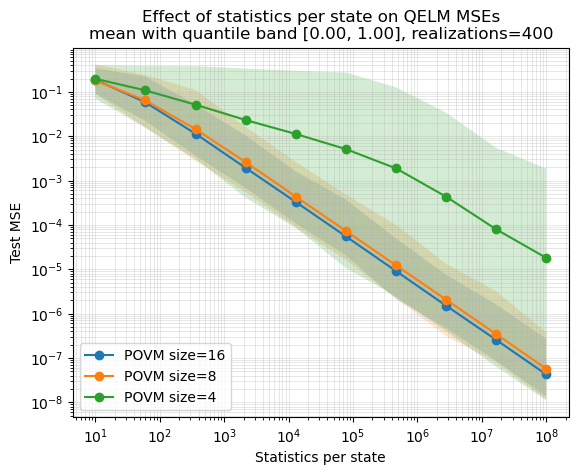

In [7]:
n_realizations = 400
dim = 2
num_outcomes = 2**4
n_train_kets = 100
n_test_kets = 100
stat_per_state_list = np.logspace(np.log10(10), np.log10(1e8), num=10).astype(int)
q_lo, q_hi = 0, 1      # e.g. IQR band; change to (0.1,0.9) etc.
# -----------------------------
# run many realizations
# -----------------------------
rows = []
for r in tqdm(range(n_realizations), desc="realizations"):
    povm_2 = random_rank1_povm(dim=2, num_outcomes=2**2)
    povm_3 = random_rank1_povm(dim=2, num_outcomes=2**3)
    povm_4 = random_rank1_povm(dim=2, num_outcomes=2**4)

    for povm_idx in range(3):
        povm = [povm_4, povm_3, povm_2][povm_idx]
        for stat_per_state in tqdm(stat_per_state_list, leave=False, desc=f"povm_idx={povm_idx}"):
            qelm = QELM.train_from_observables_and_states(
                target_observables=QuantumOperator(qutip.sigmax().full()),
                training_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_kets)),
                test_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_test_kets)),
                povm=povm,
                statistics=stat_per_state
            )
            qelm.compute_MSE(train=True, test=True, display_results=False)

            rows.append({
                "realization": r,
                "povm_size_idx": povm_idx,
                "povm_size": 2**(4 - povm_idx),
                "stat_per_state": stat_per_state,
                "train_MSE": float(qelm.train_MSE[0]),
                "test_MSE": float(qelm.test_MSE[0]),
            })

        # marginalize one output qubit: pairwise sum POVM elements
        povm = POVM(povm[0::2] + povm[1::2])

df = pd.DataFrame(rows)

# -----------------------------
# aggregate: mean + quantiles over realizations
# -----------------------------
g = df.groupby(["povm_size_idx", "povm_size", "stat_per_state"])

agg = g.agg(
    test_mean=("test_MSE", "mean"),
    test_qlo=("test_MSE", lambda x: np.quantile(x, q_lo)),
    test_qhi=("test_MSE", lambda x: np.quantile(x, q_hi)),
    train_mean=("train_MSE", "mean"),
    train_qlo=("train_MSE", lambda x: np.quantile(x, q_lo)),
    train_qhi=("train_MSE", lambda x: np.quantile(x, q_hi)),
).reset_index()

# -----------------------------
# plot: TEST (mean + band)
# -----------------------------
plt.figure()
for povm_idx in sorted(agg["povm_size_idx"].unique()):
    a = agg[agg["povm_size_idx"] == povm_idx].sort_values("stat_per_state")
    x = a["stat_per_state"].to_numpy()
    y = a["test_mean"].to_numpy()
    ylo = a["test_qlo"].to_numpy()
    yhi = a["test_qhi"].to_numpy()

    plt.plot(x, y, marker="o", label=f"POVM size={int(a['povm_size'].iloc[0])}")
    plt.fill_between(x, ylo, yhi, alpha=0.2)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Statistics per state")
plt.ylabel("Test MSE")
plt.title(
    "Effect of statistics per state on QELM MSEs\n"
    f"mean with quantile band [{q_lo:.2f}, {q_hi:.2f}], realizations={n_realizations}"
)
plt.grid(True, which="both", alpha=0.3, linewidth=0.7)
plt.legend()
plt.show()


Drawing a random 4-qubit povm and then marginilising to get the smaller ones

realizations: 100%|██████████| 200/200 [00:14<00:00, 14.27it/s]


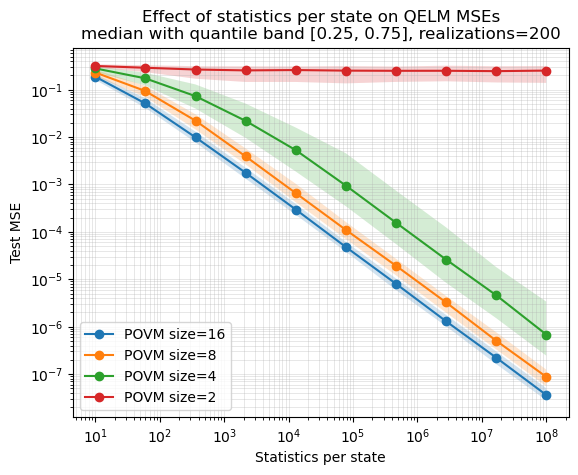

In [19]:
n_realizations = 200          # <-- set this
dim = 2
num_outcomes = 2**4
n_train_kets = 100
n_test_kets = 100
stat_per_state_list = np.logspace(np.log10(10), np.log10(1e8), num=10).astype(int)
q_lo, q_hi = 0.25, 0.75      # e.g. IQR band; change to (0.1,0.9) etc.

# -----------------------------
# run many realizations
# -----------------------------
rows = []
for r in tqdm(range(n_realizations), desc="realizations"):
    povm = random_rank1_povm(dim=dim, num_outcomes=num_outcomes)

    for povm_idx in range(4):
        for stat_per_state in tqdm(stat_per_state_list, leave=False, desc=f"povm_idx={povm_idx}"):
            qelm = QELM.train_from_observables_and_states(
                target_observables=QuantumOperator(qutip.sigmax().full()),
                training_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_kets)),
                test_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_test_kets)),
                povm=povm,
                statistics=stat_per_state
            )
            qelm.compute_MSE(train=True, test=True, display_results=False)

            rows.append({
                "realization": r,
                "povm_size_idx": povm_idx,
                "povm_size": 2**(4 - povm_idx),
                "stat_per_state": stat_per_state,
                "train_MSE": float(qelm.train_MSE[0]),
                "test_MSE": float(qelm.test_MSE[0]),
            })

        # marginalize one output qubit: pairwise sum POVM elements
        povm = POVM(povm[0::2] + povm[1::2])

df = pd.DataFrame(rows)

# -----------------------------
# aggregate: median + quantiles over realizations
# -----------------------------
g = df.groupby(["povm_size_idx", "povm_size", "stat_per_state"])

agg = g.agg(
    test_median=("test_MSE", "median"),
    test_qlo=("test_MSE", lambda x: np.quantile(x, q_lo)),
    test_qhi=("test_MSE", lambda x: np.quantile(x, q_hi)),
    train_median=("train_MSE", "median"),
    train_qlo=("train_MSE", lambda x: np.quantile(x, q_lo)),
    train_qhi=("train_MSE", lambda x: np.quantile(x, q_hi)),
).reset_index()

# -----------------------------
# plot: TEST (median + band)
# -----------------------------
plt.figure()
for povm_idx in sorted(agg["povm_size_idx"].unique()):
    a = agg[agg["povm_size_idx"] == povm_idx].sort_values("stat_per_state")
    x = a["stat_per_state"].to_numpy()
    y = a["test_median"].to_numpy()
    ylo = a["test_qlo"].to_numpy()
    yhi = a["test_qhi"].to_numpy()

    plt.plot(x, y, marker="o", label=f"POVM size={int(a['povm_size'].iloc[0])}")
    plt.fill_between(x, ylo, yhi, alpha=0.2)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Statistics per state")
plt.ylabel("Test MSE")
plt.title(
    "Effect of statistics per state on QELM MSEs\n"
    f"median with quantile band [{q_lo:.2f}, {q_hi:.2f}], realizations={n_realizations}"
)
plt.grid(True, which="both", alpha=0.3, linewidth=0.7)
plt.legend()
plt.show()

# -----------------------------
# plot: TRAIN (median + band)  (optional)
# -----------------------------
# plt.figure()
# for povm_idx in sorted(agg["povm_size_idx"].unique()):
#     a = agg[agg["povm_size_idx"] == povm_idx].sort_values("stat_per_state")
#     x = a["stat_per_state"].to_numpy()
#     y = a["train_median"].to_numpy()
#     ylo = a["train_qlo"].to_numpy()
#     yhi = a["train_qhi"].to_numpy()

#     plt.plot(x, y, marker="o", label=f"POVM size={int(a['povm_size'].iloc[0])}")
#     plt.fill_between(x, ylo, yhi, alpha=0.2)

# plt.xscale("log")
# plt.yscale("log")
# plt.xlabel("Statistics per state")
# plt.ylabel("Train MSE")
# plt.title(
#     "Effect of statistics per state on QELM MSEs (TRAIN)\n"
#     f"median with quantile band [{q_lo:.2f}, {q_hi:.2f}], realizations={n_realizations}"
# )
# plt.grid(True, which="both")
# plt.legend()
# plt.show()


realizations: 100%|██████████| 200/200 [00:13<00:00, 14.70it/s]


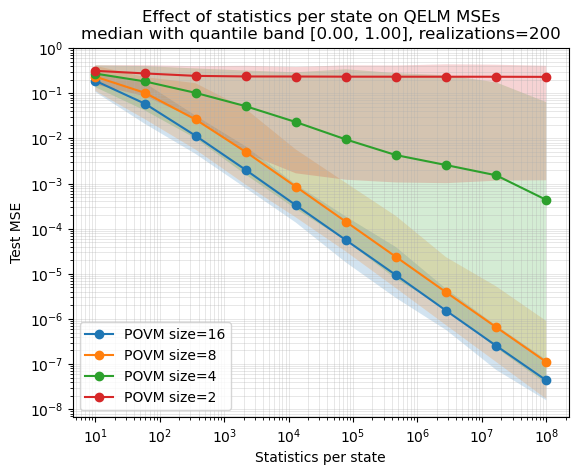

In [40]:
n_realizations = 200          # <-- set this
dim = 2
num_outcomes = 2**4
n_train_kets = 100
n_test_kets = 100
stat_per_state_list = np.logspace(np.log10(10), np.log10(1e8), num=10).astype(int)
q_lo, q_hi = 0, 1      # e.g. IQR band; change to (0.1,0.9) etc.

# -----------------------------
# run many realizations
# -----------------------------
rows = []
for r in tqdm(range(n_realizations), desc="realizations"):
    povm = random_rank1_povm(dim=dim, num_outcomes=num_outcomes)

    for povm_idx in range(4):
        for stat_per_state in tqdm(stat_per_state_list, leave=False, desc=f"povm_idx={povm_idx}"):
            qelm = QELM.train_from_observables_and_states(
                target_observables=QuantumOperator(qutip.sigmax().full()),
                training_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_train_kets)),
                test_states=QuantumKetsBatch(random_kets(dim=dim, num_kets=n_test_kets)),
                povm=povm,
                statistics=stat_per_state
            )
            qelm.compute_MSE(train=True, test=True, display_results=False)

            rows.append({
                "realization": r,
                "povm_size_idx": povm_idx,
                "povm_size": 2**(4 - povm_idx),
                "stat_per_state": stat_per_state,
                "train_MSE": float(qelm.train_MSE[0]),
                "test_MSE": float(qelm.test_MSE[0]),
            })

        # marginalize one output qubit: pairwise sum POVM elements
        povm = POVM(povm[0::2] + povm[1::2])

df = pd.DataFrame(rows)

# -----------------------------
# aggregate: median + quantiles over realizations
# -----------------------------
g = df.groupby(["povm_size_idx", "povm_size", "stat_per_state"])

agg = g.agg(
    test_mean=("test_MSE", "mean"),
    test_qlo=("test_MSE", lambda x: np.quantile(x, q_lo)),
    test_qhi=("test_MSE", lambda x: np.quantile(x, q_hi)),
    train_mean=("train_MSE", "mean"),
    train_qlo=("train_MSE", lambda x: np.quantile(x, q_lo)),
    train_qhi=("train_MSE", lambda x: np.quantile(x, q_hi)),
).reset_index()

# -----------------------------
# plot: TEST (median + band)
# -----------------------------
plt.figure()
for povm_idx in sorted(agg["povm_size_idx"].unique()):
    a = agg[agg["povm_size_idx"] == povm_idx].sort_values("stat_per_state")
    x = a["stat_per_state"].to_numpy()
    y = a["test_mean"].to_numpy()
    ylo = a["test_qlo"].to_numpy()
    yhi = a["test_qhi"].to_numpy()

    plt.plot(x, y, marker="o", label=f"POVM size={int(a['povm_size'].iloc[0])}")
    plt.fill_between(x, ylo, yhi, alpha=0.2)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Statistics per state")
plt.ylabel("Test MSE")
plt.title(
    "Effect of statistics per state on QELM MSEs\n"
    f"median with quantile band [{q_lo:.2f}, {q_hi:.2f}], realizations={n_realizations}"
)
plt.grid(True, which="both", alpha=0.3, linewidth=0.7)
plt.legend()
plt.show()

In [61]:
# print this numpy array in a way that i can copy paste in wolfram mathematica
# remembering that scientific notation like 7e-07 should be written as 7*10^-7
arr = df_subset['test_MSE'].to_numpy()
print("{", end="")
print(", ".join([f"{x:.6e}".replace("e", "*10^") for x in arr]), end="")

{7.609436*10^-08, 5.128795*10^-07, 1.992285*10^-06, 3.539855*10^-07, 8.613477*10^-08, 4.268321*10^-07, 1.708501*10^-05, 2.918748*10^-07, 6.353469*10^-07, 3.580446*10^-07, 1.888503*10^-07, 3.197238*10^-06, 8.071151*10^-08, 5.544250*10^-07, 1.048538*10^-07, 1.074567*10^-07, 3.159183*10^-04, 8.957011*10^-08, 2.478923*10^-07, 4.179354*10^-08, 9.346250*10^-06, 5.064064*10^-07, 2.539533*10^-06, 3.808991*10^-05, 1.634913*10^-06, 8.486397*10^-07, 1.501291*10^-05, 2.397375*10^-05, 3.089891*10^-07, 1.542341*10^-06, 2.568102*10^-07, 1.841227*10^-07, 6.366311*10^-02, 1.431181*10^-06, 1.378887*10^-06, 4.096669*10^-05, 5.969630*10^-06, 3.162006*10^-07, 3.249797*10^-07, 3.992940*10^-05, 6.661565*10^-07, 1.709484*10^-06, 6.925502*10^-07, 1.604498*10^-07, 2.852674*10^-05, 9.771982*10^-06, 2.153668*10^-06, 1.554106*10^-07, 1.570257*10^-06, 3.212684*10^-07, 1.124949*10^-06, 4.165271*10^-07, 1.577582*10^-05, 2.945971*10^-07, 5.037076*10^-07, 1.225123*10^-07, 2.011208*10^-03, 1.774581*10^-07, 2.614120*10^-

# Code to compute Heisenberg representation in general cases

In [ ]:
import numpy as np
from typing import List, Dict, Tuple, Optional, Sequence, Union

class MeasurementApparatus:
    def __init__(self, input_dim: int):
        """
        Measurement apparatus acting on an initial 'input' register of given dimension.

        The internal Hilbert space is a tensor product of labeled registers.
        Registers are stored in a fixed order, and ancillas are always appended
        at the right (last tensor factor).
        """
        self.input_dim = input_dim
        # List of register labels in tensor-product order.
        self.registers: List[str] = ['input']
        # Map from register label to its Hilbert-space dimension.
        self.dims: Dict[str, int] = {'input': input_dim}
        # Ancilla states (density matrices) by label.
        self.ancilla_states: Dict[str, np.ndarray] = {}
        # Sequence of steps: ('add_ancilla', label, state),
        # ('apply_unitary', labels_str, unitary),
        # ('measure', label, basis)
        self.steps: List[Tuple] = []
        # After effective_povm(), we can optionally store outcome tuples here:
        #   index -> tuple of ( (label, outcome_index), ... ) in forward time order.
        self.outcome_tuples: Optional[List[Tuple[Tuple[str, int], ...]]] = None

    # ----------------------------------------------------------------------
    # Helper methods (internal)
    # ----------------------------------------------------------------------
    @staticmethod
    def _total_dim(dims: Sequence[int]) -> int:
        """Product of all dimensions in dims."""
        d = 1
        for x in dims:
            d *= x
        return d

    def _current_total_dim(self) -> int:
        """Total Hilbert-space dimension of all registers."""
        dims_list = [self.dims[label] for label in self.registers]
        return self._total_dim(dims_list)

    @staticmethod
    def _permutation_matrix(dims: Sequence[int], new_order: Sequence[int]) -> np.ndarray:
        """
        Build the permutation matrix P that maps basis from the original
        tensor ordering to the new ordering given by new_order.

        Input:
            dims: list of dims [d0, d1, ..., d_{n-1}]
            new_order: permutation of indices [0..n-1]

        P satisfies: |i_{new_0},...,i_{new_{n-1}}> = P |i_0,...,i_{n-1}>.
        """
        dims = list(dims)
        n = len(dims)
        assert set(new_order) == set(range(n)), "new_order must be a permutation."
        D = 1
        for d in dims:
            D *= d

        # dims_new in new tensor order
        dims_new = [dims[i] for i in new_order]

        P = np.zeros((D, D), dtype=np.complex128)
        for old_index in range(D):
            # Multi-index in old ordering
            old_multi = np.unravel_index(old_index, dims)
            # Multi-index in new ordering
            new_multi = tuple(old_multi[i] for i in new_order)
            new_index = np.ravel_multi_index(new_multi, dims_new)
            P[new_index, old_index] = 1.0
        return P

    def _embed_unitary(
        self,
        unitary: np.ndarray,
        target_labels: Sequence[str],
        all_labels: Sequence[str],
        dims_map: Dict[str, int],
    ) -> np.ndarray:
        """
        Embed a unitary acting on target_labels into the full Hilbert space.

        Given target_labels (ordered as the unitary acts) and the complete
        list all_labels (current tensor order), construct:

            U_full = P^† (U_target ⊗ I_rest) P

        where P permutes the tensor factors so that the targets are grouped
        first, followed by the rest, preserving the relative order within
        each group.
        """
        if len(target_labels) == 0:
            raise ValueError("apply_unitary must act on at least one register.")

        all_labels = list(all_labels)
        dims_list = [dims_map[lbl] for lbl in all_labels]
        total_dim = self._total_dim(dims_list)

        # Indices of target registers in the current ordering
        target_indices = [all_labels.index(lbl) for lbl in target_labels]
        rest_indices = [i for i in range(len(all_labels)) if i not in target_indices]

        # Dimensions
        dim_target = 1
        for idx in target_indices:
            dim_target *= dims_list[idx]
        dim_rest = total_dim // dim_target

        # Check unitary dimension
        if unitary.shape != (dim_target, dim_target):
            raise ValueError(
                f"Unitary dimension {unitary.shape} does not match product of target dims {dim_target}."
            )

        # Build permutation P that reorders registers to [targets..., rest...]
        new_order = target_indices + rest_indices
        P = self._permutation_matrix(dims_list, new_order)

        # Build (U_target ⊗ I_rest) in the permuted ordering
        U_big = np.kron(unitary, np.eye(dim_rest, dtype=np.complex128))

        # Transform back to original ordering
        U_full = P.conj().T @ U_big @ P
        return U_full

    def _measurement_projectors_local(self, d: int, basis: Optional[np.ndarray]) -> List[np.ndarray]:
        """
        Construct projectors {P_m} on a single d-dimensional register.

        basis = None:
            computational basis |m>.
        basis = unitary matrix U (d x d):
            basis vectors are columns of U; projectors P_m = |φ_m><φ_m|
            with |φ_m> = U |m>.
        """
        if basis is None:
            # Computational basis projectors
            projectors = []
            for m in range(d):
                Pm = np.zeros((d, d), dtype=np.complex128)
                Pm[m, m] = 1.0
                projectors.append(Pm)
            return projectors

        # Treat basis as a unitary whose columns are the basis kets
        U = np.asarray(basis, dtype=np.complex128)
        if U.shape != (d, d):
            raise ValueError("Basis operator must be a square d x d unitary for this register.")

        # P_m = |φ_m><φ_m|, with |φ_m> the m-th column of U
        projectors = []
        for m in range(d):
            phi = U[:, m]
            Pm = np.outer(phi, phi.conj())
            projectors.append(Pm)
        return projectors

    def _embed_single_register_projector(
        self,
        P_local: np.ndarray,
        reg_index: int,
        dims_list: Sequence[int],
    ) -> np.ndarray:
        """
        Embed a single-register projector P_local (dim d_r x d_r) acting on register
        at position reg_index into the full tensor product Hilbert space.

        Using permutation to bring that register first: [reg_index, others...],
        then embed as (P_local ⊗ I_rest), and permute back.
        """
        dims_list = list(dims_list)
        n = len(dims_list)
        if not (0 <= reg_index < n):
            raise IndexError("Register index out of range.")

        d_r = dims_list[reg_index]
        total_dim = self._total_dim(dims_list)
        if P_local.shape != (d_r, d_r):
            raise ValueError("Local projector dimension mismatch.")

        # Permutation to put reg_index first
        rest_indices = [i for i in range(n) if i != reg_index]
        new_order = [reg_index] + rest_indices
        P_perm = self._permutation_matrix(dims_list, new_order)

        dim_rest = total_dim // d_r
        I_rest = np.eye(dim_rest, dtype=np.complex128)

        P_big = np.kron(P_local, I_rest)
        P_full = P_perm.conj().T @ P_big @ P_perm
        return P_full

    @staticmethod
    def _reduce_rightmost_ancilla_dual(
        effect_full: np.ndarray,
        sigma: np.ndarray,
        dim_sys: int,
        dim_anc: int,
    ) -> np.ndarray:
        """
        Dual map for adding an ancilla on the rightmost tensor factor.

        Forward channel (Schrödinger):
            Φ(ρ_sys) = ρ_sys ⊗ σ_anc

        Dual map (Heisenberg):
            given X on H_sys ⊗ H_anc, find E on H_sys s.t.
                Tr[X (ρ ⊗ σ)] = Tr[E ρ]   for all ρ.

        The explicit formula used here is:

            E_{ij} = Tr[ X ( |j><i| ⊗ σ ) ]

        where {|i>} is any fixed orthonormal basis of H_sys.
        """
        D_sys = dim_sys
        D_anc = dim_anc
        D_total = D_sys * D_anc

        if effect_full.shape != (D_total, D_total):
            raise ValueError("effect_full dimension does not match sys ⊗ anc dimensions.")
        if sigma.shape != (D_anc, D_anc):
            raise ValueError("Ancilla state sigma has inconsistent dimension.")

        E = np.zeros((D_sys, D_sys), dtype=np.complex128)

        # Precompute kron basis with sigma for each |j><i|
        # E[i, j] = Tr[ effect_full @ (|j><i| ⊗ sigma) ]
        for i in range(D_sys):
            for j in range(D_sys):
                B_ji = np.zeros((D_sys, D_sys), dtype=np.complex128)
                B_ji[j, i] = 1.0
                X_ji = np.kron(B_ji, sigma)
                E[i, j] = np.trace(effect_full @ X_ji)

        # Make Hermitian numerically (rounding errors)
        E = 0.5 * (E + E.conj().T)
        return E

    # ----------------------------------------------------------------------
    # Public building interface
    # ----------------------------------------------------------------------
    def add_ancilla_register(self, label: str, state: 'QuantumState') -> "MeasurementApparatus":
        """Add ancilla register with given label and initial QuantumState."""
        if label in self.registers:
            raise ValueError(f"Register label '{label}' already exists.")
        if not hasattr(state, "dim"):
            raise ValueError("Ancilla QuantumState must have a 'dim' attribute.")

        self.registers.append(label)
        self.dims[label] = int(state.dim)
        # Store density matrix of ancilla state
        sigma = state.todm().data  # expecting QuantumDensityMatrix-like with .data
        self.ancilla_states[label] = np.asarray(sigma, dtype=np.complex128)
        self.steps.append(('add_ancilla', label, state))
        return self

    def apply_unitary(self, labels: str, unitary: 'QuantumOperator') -> "MeasurementApparatus":
        """
        Apply unitary operation on specified registers.

        Parameters
        ----------
        labels : str
            Comma-separated labels of registers the unitary acts on,
            in the order corresponding to the tensor ordering of the unitary.
        unitary : QuantumOperator
            Unitary operator on the tensor product of the specified registers.
        """
        label_list = [s.strip() for s in labels.split(',') if s.strip()]
        if len(label_list) == 0:
            raise ValueError("At least one label must be specified for apply_unitary.")
        for lbl in label_list:
            if lbl not in self.registers:
                raise ValueError(f"Unknown register label '{lbl}' in apply_unitary.")

        self.steps.append(('apply_unitary', labels, unitary))
        return self

    def measure_register(
        self,
        label: str,
        basis: Optional['QuantumOperator'] = None
    ) -> "MeasurementApparatus":
        """
        Measure given register in specified basis.

        Parameters
        ----------
        label : str
            Label of register to be measured.
        basis : QuantumOperator or None
            If None: projective measurement in the computational basis of the register.
            If QuantumOperator: treated as a unitary whose columns define the basis
            in which a projective measurement is performed.
        """
        if label not in self.registers:
            raise ValueError(f"Unknown register label '{label}' in measure_register.")

        self.steps.append(('measure', label, basis))
        return self

    # ----------------------------------------------------------------------
    # Backward Heisenberg construction of effective POVM
    # ----------------------------------------------------------------------
    def effective_povm(self) -> POVM:
        """
        Compute the effective POVM implemented by the apparatus on the
        original input space.

        The algorithm proceeds in the Heisenberg picture:

        1. Start from the identity operator on the final total Hilbert space.
        2. Traverse the steps in reverse.
           - For each measurement, expand the current set of effects by
             sandwiching with the projectors corresponding to each outcome.
           - For each unitary, conjugate all effects by the corresponding
             embedded unitary.
           - For each ancilla addition, apply the dual map for ρ -> ρ ⊗ σ,
             effectively removing the ancilla register and obtaining effects
             on the reduced space.
        3. At the end we obtain a set of POVM elements acting on the original
           input Hilbert space.

        The returned POVM elements are ordered according to the lexicographic
        combination of measurement outcomes encountered in forward time.
        The mapping from element index to the tuple of outcomes is stored in
        self.outcome_tuples as a list of tuples of (label, outcome_index).
        """
        # Current registers and dims at the final time
        current_registers = list(self.registers)
        current_dims_map = dict(self.dims)
        dims_list = [current_dims_map[lbl] for lbl in current_registers]
        total_dim = self._total_dim(dims_list)

        # Start with a single effect: identity on the final Hilbert space
        effects: List[np.ndarray] = [np.eye(total_dim, dtype=np.complex128)]
        # Keep track of classical outcome tuples for each effect
        # We build them backward and will reverse the order at the end.
        outcome_tags: List[Tuple[Tuple[str, int], ...]] = [tuple()]

        # Traverse steps in reverse order
        for step in reversed(self.steps):
            kind = step[0]

            if kind == 'apply_unitary':
                _, labels_str, unitary_obj = step
                labels_list = [s.strip() for s in labels_str.split(',') if s.strip()]
                U_target = np.asarray(unitary_obj.data, dtype=np.complex128)

                dims_list = [current_dims_map[lbl] for lbl in current_registers]
                U_full = self._embed_unitary(
                    U_target,
                    target_labels=labels_list,
                    all_labels=current_registers,
                    dims_map=current_dims_map,
                )
                U_dag = U_full.conj().T

                # Conjugate all effects: E -> U† E U
                effects = [U_dag @ E @ U_full for E in effects]

            elif kind == 'measure':
                _, label, basis_op = step
                # Dimension list at this time
                dims_list = [current_dims_map[lbl] for lbl in current_registers]
                reg_index = current_registers.index(label)
                d_r = dims_list[reg_index]

                # Local basis operator (if provided)
                if basis_op is None:
                    basis_matrix = None
                else:
                    basis_matrix = np.asarray(basis_op.data, dtype=np.complex128)

                # Local projectors {P_m} on this register
                local_projectors = self._measurement_projectors_local(d_r, basis_matrix)

                # Embed each local projector in the full space
                projectors_full = []
                for P_loc in local_projectors:
                    P_full = self._embed_single_register_projector(
                        P_loc, reg_index, dims_list
                    )
                    projectors_full.append(P_full)

                # For each existing effect and each outcome m, create new effect:
                #   E'_{(m, tag)} = P_m E_tag P_m
                new_effects: List[np.ndarray] = []
                new_tags: List[Tuple[Tuple[str, int], ...]] = []

                for E, tag in zip(effects, outcome_tags):
                    for m, Pm in enumerate(projectors_full):
                        Em = Pm @ E @ Pm
                        new_effects.append(Em)
                        # Prepend this measurement outcome; we will fix order at the end
                        new_tags.append(((label, m),) + tag)

                effects = new_effects
                outcome_tags = new_tags

            elif kind == 'add_ancilla':
                _, label, state = step
                # At this backward point, the ancilla register must be present
                # and (by construction) it is the last register in the tensor order.
                if current_registers[-1] != label:
                    raise RuntimeError(
                        "Ancilla registers are assumed to be appended at the end. "
                        f"Encountered 'add_ancilla' for label '{label}' but the last "
                        f"register is '{current_registers[-1]}'."
                    )

                # Dimensions and sigma
                d_anc = current_dims_map[label]
                dims_list = [current_dims_map[lbl] for lbl in current_registers]
                total_dim = self._total_dim(dims_list)
                dim_sys = total_dim // d_anc

                sigma = self.ancilla_states[label]
                if sigma.shape != (d_anc, d_anc):
                    raise ValueError(f"Stored ancilla state for '{label}' has wrong dimension.")

                # Apply dual map to each effect to remove this ancilla
                new_effects = []
                for E_full in effects:
                    E_sys = self._reduce_rightmost_ancilla_dual(
                        effect_full=E_full,
                        sigma=sigma,
                        dim_sys=dim_sys,
                        dim_anc=d_anc,
                    )
                    new_effects.append(E_sys)

                effects = new_effects

                # Remove ancilla from current registers/dims
                current_registers.pop()
                current_dims_map.pop(label)

            else:
                raise ValueError(f"Unknown step kind '{kind}' encountered.")

        # At this point, effects act on the initial Hilbert space.
        # Typically this should be only the 'input' register.
        final_registers = current_registers
        if final_registers != ['input']:
            # If there are leftover registers (e.g., if the user constructed
            # something unusual), we leave effects on the full space defined
            # by final_registers. The user can then decide how to interpret them.
            pass

        # Ensure numerical Hermiticity and positivity-ish (clip small negatives on diagonal)
        povm_elems = []
        for E in effects:
            E = 0.5 * (E + E.conj().T)
            # Optionally, we might want to clip tiny negative eigenvalues, but
            # we will not modify spectra here beyond Hermitisation.
            povm_elems.append(E)

        povm_array = np.stack(povm_elems, axis=0)
        povm = POVM(povm_array, label=f"effective POVM with {len(povm_elems)} outcomes")

        # Store the mapping from index to outcome tuples in forward time order:
        # outcome_tags were built backward; reverse each tuple.
        self.outcome_tuples = [tuple(reversed(tag)) for tag in outcome_tags]

        return povm


In [ ]:
# Suppose input qubit (dim = 2)
M = MeasurementApparatus(input_dim=2)
# Measure in computational basis {|0>, |1>}
M.measure_register("input", basis=None)

print(M.effective_povm().data)

[[[1.+0.j 0.+0.j]
  [0.+0.j 0.+0.j]]

 [[0.+0.j 0.+0.j]
  [0.+0.j 1.+0.j]]]


In [32]:
# print the 2-qubit (4x4) fourier transform
U_ft = (1/2) * np.array([
    [1, 1, 1, 1],
    [1, 1j, -1, -1j],
    [1, -1, 1, -1],
    [1, -1j, -1, 1j]
], dtype=np.complex128)

In [29]:
from qiskit.quantum_info import Operator
hadamard_matrix = Operator.from_label('H').data
# Suppose input qubit (dim = 2)
M = MeasurementApparatus(input_dim=2)
# evolve with Hadamard
M.apply_unitary("input", QuantumOperator(hadamard_matrix))
# Measure in computational basis {|0>, |1>}
M.measure_register("input", basis=None)

print(M.effective_povm().data)


[[[ 0.5+0.j  0.5+0.j]
  [ 0.5+0.j  0.5+0.j]]

 [[ 0.5+0.j -0.5+0.j]
  [-0.5+0.j  0.5+0.j]]]


In [43]:
# Input is a single qubit
M = MeasurementApparatus(input_dim=2)

# Ancilla in |0>
anc = QuantumKet(np.array([1, 0]))
M.add_ancilla_register("anc", anc)

# 2-qubit unitary acting on ("input", "anc")
Uop = QuantumOperator(U_ft)

M.apply_unitary("input, anc", Uop)

# Now measure ancilla only
M.measure_register("anc")
M.measure_register("input")

POVM_eff = M.effective_povm()

print("Number of POVM outcomes:", len(POVM_eff))
print("POVM elements:\n", POVM_eff.data)
print(M.outcome_tuples)


Number of POVM outcomes: 4
POVM elements:
 [[[ 0.25+0.j  0.25+0.j]
  [ 0.25+0.j  0.25+0.j]]

 [[ 0.25+0.j -0.25+0.j]
  [-0.25+0.j  0.25+0.j]]

 [[ 0.25+0.j  0.25+0.j]
  [ 0.25+0.j  0.25+0.j]]

 [[ 0.25+0.j -0.25+0.j]
  [-0.25+0.j  0.25+0.j]]]
[(('input', 0), ('anc', 0)), (('input', 0), ('anc', 1)), (('input', 1), ('anc', 0)), (('input', 1), ('anc', 1))]


In [45]:
# Input is a single qubit
M = MeasurementApparatus(input_dim=2)

# Ancilla in |0>
anc = QuantumKet(np.array([1, 0]))
M.add_ancilla_register("anc", anc)
M.add_ancilla_register("trash", anc)

# 2-qubit unitary acting on ("input", "anc")
Uop = QuantumOperator(U_ft)

M.apply_unitary("input, anc", Uop)

# Now measure everything
M.measure_register("anc")
M.measure_register("input")
M.measure_register("trash")

POVM_eff = M.effective_povm()

print("Number of POVM outcomes:", len(POVM_eff))
print("POVM elements:\n", POVM_eff.data)
for idx, tag in enumerate(M.outcome_tuples):
    print(idx, "->", tag)


Number of POVM outcomes: 8
POVM elements:
 [[[ 0.25+0.j  0.25+0.j]
  [ 0.25+0.j  0.25+0.j]]

 [[ 0.25+0.j -0.25+0.j]
  [-0.25+0.j  0.25+0.j]]

 [[ 0.25+0.j  0.25+0.j]
  [ 0.25+0.j  0.25+0.j]]

 [[ 0.25+0.j -0.25+0.j]
  [-0.25+0.j  0.25+0.j]]

 [[ 0.  +0.j  0.  +0.j]
  [ 0.  +0.j  0.  +0.j]]

 [[ 0.  +0.j  0.  +0.j]
  [ 0.  +0.j  0.  +0.j]]

 [[ 0.  +0.j  0.  +0.j]
  [ 0.  +0.j  0.  +0.j]]

 [[ 0.  +0.j  0.  +0.j]
  [ 0.  +0.j  0.  +0.j]]]
0 -> (('trash', 0), ('input', 0), ('anc', 0))
1 -> (('trash', 0), ('input', 0), ('anc', 1))
2 -> (('trash', 0), ('input', 1), ('anc', 0))
3 -> (('trash', 0), ('input', 1), ('anc', 1))
4 -> (('trash', 1), ('input', 0), ('anc', 0))
5 -> (('trash', 1), ('input', 0), ('anc', 1))
6 -> (('trash', 1), ('input', 1), ('anc', 0))
7 -> (('trash', 1), ('input', 1), ('anc', 1))


In [39]:
M = MeasurementApparatus(input_dim=2)

# Step 1: add B = ancilla 1
B = QuantumKet(np.array([1, 0]))
M.add_ancilla_register("B", B)

# Step 2: apply first 2-qubit unitary U1 on (input, B)
U1 = qutip.rand_unitary(4).full()           # any 4×4 unitary
M.apply_unitary("input, B", QuantumOperator(U1))

# Step 3: measure B
M.measure_register("B")

# Step 4: add C = ancilla 2
C = QuantumKet(np.array([1, 0]))
M.add_ancilla_register("C", C)

# Step 5: apply second 2-qubit unitary U2 on (input, C)
U2 = qutip.rand_unitary(4).full()
M.apply_unitary("input, C", QuantumOperator(U2))

# Step 6: measure input
M.measure_register("input")

# Compute the effective POVM
POVM_eff = M.effective_povm()

print("Total outcomes:", len(POVM_eff))
print("POVM elements:\n", POVM_eff.data)
for idx, tag in enumerate(M.outcome_tuples):
    print(idx, "->", tag)


Total outcomes: 4
POVM elements:
 [[[ 0.09258155+0.j         -0.17820314+0.02439712j]
  [-0.17820314-0.02439712j  0.42240793+0.j        ]]

 [[ 0.44831128+0.j          0.12573217+0.00823714j]
  [ 0.12573217-0.00823714j  0.03755982+0.j        ]]

 [[ 0.01732901+0.j         -0.08989149-0.00089666j]
  [-0.08989149+0.00089666j  0.49173425+0.j        ]]

 [[ 0.44177817+0.j          0.14236246-0.0317376j ]
  [ 0.14236246+0.0317376j   0.048298  +0.j        ]]]
0 -> (('input', 0), ('B', 0))
1 -> (('input', 0), ('B', 1))
2 -> (('input', 1), ('B', 0))
3 -> (('input', 1), ('B', 1))
